<a href="https://colab.research.google.com/github/Aish-leksh/Assessment_NumPy-and-Pandas/blob/main/Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/DSAB13/Datasets/Social_Network_Ads.csv")
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [ ]:
df.shape

(400, 5)

In [ ]:
df.columns

Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

In [ ]:
df['User ID'].nunique()

400

In [ ]:
df.drop("User ID", axis=1, inplace=True, errors='ignore')
df.head()

,Gender,Age,EstimatedSalary,Purchased
0,Male,19,19000,0
1,Male,35,20000,0
2,Female,26,43000,0
3,Female,27,57000,0
4,Male,19,76000,0


In [ ]:
df.isnull().sum()

,0
Gender,0
Age,0
EstimatedSalary,0
Purchased,0


In [ ]:
df.dtypes

,0
Gender,object
Age,int64
EstimatedSalary,int64
Purchased,int64


In [ ]:
df['Gender'].nunique()

2

In [ ]:
pd.get_dummies(df['Gender']).head()

,Female,Male
0,False,True
1,False,True
2,True,False
3,True,False
4,False,True


In [ ]:
pd.get_dummies(df, prefix='Gender', dtype=int).head()

,Age,EstimatedSalary,Purchased,Gender_Female,Gender_Male
0,19,19000,0,0,1
1,35,20000,0,0,1
2,26,43000,0,1,0
3,27,57000,0,1,0
4,19,76000,0,0,1


In [ ]:
df["Purchased"].nunique()

2

In [ ]:
df["Purchased"].unique()

array([0, 1])

In [ ]:
df["Purchased"].value_counts()

,count
Purchased,
0,257
1,143


<Axes: >

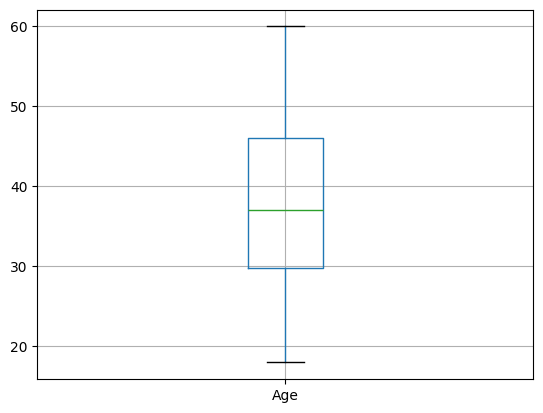

In [ ]:
df.boxplot(column='Age')

<Axes: title={'center': 'Boxplot of Salary'}>

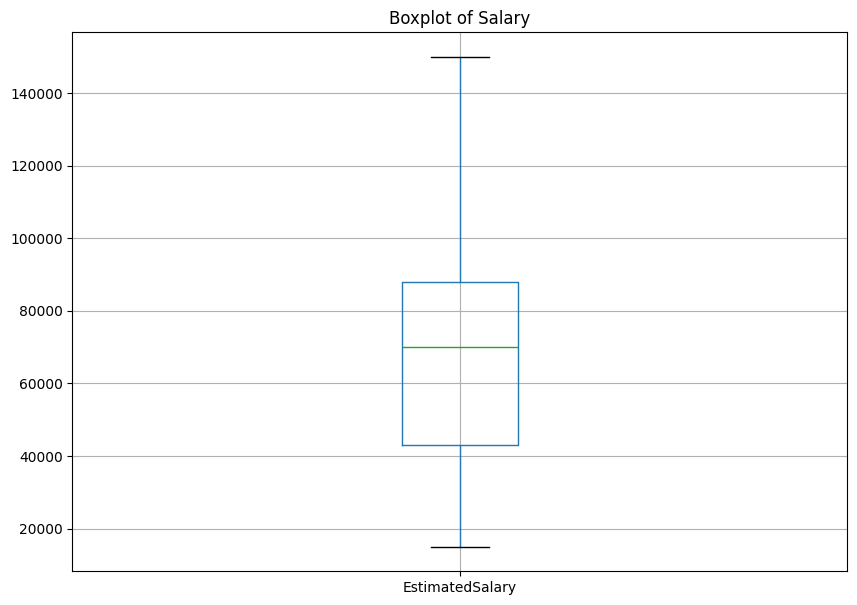

In [ ]:
plt.figure(figsize=(10, 7))
plt.title("Boxplot of Salary")
df.boxplot(column='EstimatedSalary')

In [ ]:
# Define features (x) and target (y)
x = df.drop('Purchased', axis=1)
y = df['Purchased']

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
#Logistic Regression model
from sklearn.linear_model import LogisticRegression

In logistic regression we use max itr specifies maximum number of iterations, no. of iterations the algorithm can perform while trying to find the best model parameters. 100 is the default iteration. During training LR tries to find the best coefficient for its input features. for e.g., when we are predicting wheather a customer bill purchased a product based on age, salary, gender. Initially the model does not know the best coefficient, it starts with initial parameter values, and gradually, improves them to minimize the prediction error. (log-loss)
The process is:
1.initialized model parameters
2.Calculate predictions
3.Calculate the logs
4.Update coefficients to reduce the loss
5.Repeat until convergence of the iteration limit is reached
max itr =10 may stop before convergence.
max itr =100 may or maynot converge and it is the default value.
max itr =500 more opportunity to converge.
max itr =1000 allows more iteration.

increasing max itr does not automatically, improve accuracy, but it simply gives the optimisation algorithm , more opportunity to converge.

In [ ]:
# One-hot encode the categorical variables in the dataframe
df_encoded = pd.get_dummies(df, columns=['Gender'], drop_first=True, dtype=int)

# Define features (x) and target (y)
x_encoded = df_encoded.drop('Purchased', axis=1)
y_encoded = df_encoded['Purchased']

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(x_encoded, y_encoded, test_size=0.2, random_state=42)

# Fit the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(x_train, y_train)
y_pred_lr_model = lr_model.predict(x_test)

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from sklearn.metrics import accuracy_score, f1_score

In [ ]:
print(confusion_matrix(y_test, y_pred_lr_model))
print("accuracy is: ", accuracy_score(y_test, y_pred_lr_model))
print("precision is: ", precision_score(y_test, y_pred_lr_model))
print("recall is: ", recall_score(y_test, y_pred_lr_model))
print("f1 score is: ", f1_score(y_test, y_pred_lr_model))

[[50  2]
 [ 7 21]]
accuracy is:  0.8875
precision is:  0.9130434782608695
recall is:  0.75
f1 score is:  0.8235294117647058


#KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
acc_score=[]
for k in range(3,10):
  knn=KNeighborsClassifier(n_neighbors=k)
  knn.fit(x_train,y_train)
  y_pred_knn=knn.predict(x_test)
  acc=accuracy_score(y_test,y_pred_knn)
  acc_score.append(acc)

In [ ]:
acc_score

[0.8, 0.8, 0.825, 0.775, 0.8125, 0.775, 0.8]

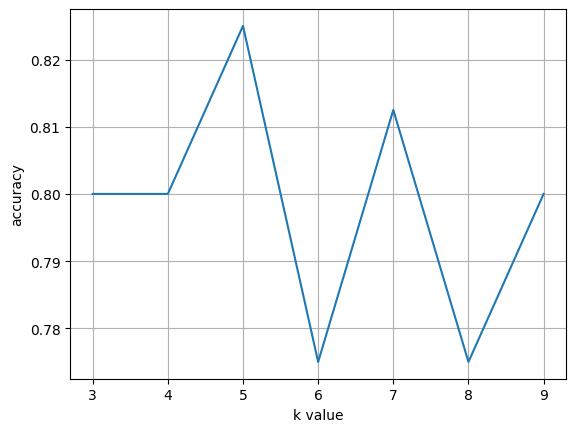

In [ ]:
plt.plot(range(3,10),acc_score)
plt.xlabel("k value")
plt.ylabel("accuracy")
plt.grid()

In [ ]:
#optimum k value is 5 because accuracy is high when k=5
#train the knn model for k=5
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train,y_train)
y_pred_knn=knn.predict(x_test)
print(confusion_matrix(y_test,y_pred_knn))
print("accuracy is: ",accuracy_score(y_test,y_pred_knn))
print("precision is: ",precision_score(y_test,y_pred_knn))
print("recall is: ",recall_score(y_test,y_pred_knn))

[[46  6]
 [ 8 20]]
accuracy is:  0.825
precision is:  0.7692307692307693
recall is:  0.7142857142857143


#SVM


In [ ]:
x1=df.copy()

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scalar = MinMaxScaler()

In [ ]:
for i in ['Age', 'EstimatedSalary']:
  x1[i] = scalar.fit_transform(x1[i].values.reshape(-1,1))

x1.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,0.467976,0.405500,0.357500
std,0.249592,0.252570,0.479864
min,0.000000,0.000000,0.000000
25%,0.279762,0.207407,0.000000
50%,0.452381,0.407407,0.000000
75%,0.666667,0.540741,1.000000
max,1.000000,1.000000,1.000000


In [ ]:
X_train1, X_test1, y_train, y_test = train_test_split(X1, y,
                                  test_size=0.2, random_state=42)

SVC stands for support vector classifier. It is a class in pythons scikit-learn library, used to perform classification task using SVM.

In [ ]:
from sklearn.svm import SVC

LINEAR KERNAL

In [ ]:
svm_linear = SVC(kernel='linear')
svm_linear.fit(X_train1, y_train)
y_pred_svm_linear = svm_linear.predict(X_test1)
print(confusion_matrix(y_test, y_pred_svm_linear))
print(accuracy_score(y_test, y_pred_svm_linear))
print(precision_score(y_test, y_pred_svm_linear))
print(recall_score(y_test, y_pred_svm_linear))
print(f1_score(y_test, y_pred_svm_linear))

[[51  1]
 [ 9 19]]
0.875
0.95
0.6785714285714286
0.7916666666666666


POLINOMIAL KERNAL

In [ ]:
svm_poly = SVC(kernel='poly')
svm_poly.fit(X_train1, y_train)
y_pred_svm_poly = svm_poly.predict(X_test1)
print(confusion_matrix(y_test, y_pred_svm_poly))
print(accuracy_score(y_test, y_pred_svm_poly))
print(precision_score(y_test, y_pred_svm_poly))
print(recall_score(y_test, y_pred_svm_poly))
print(f1_score(y_test, y_pred_svm_poly))

[[48  4]
 [ 3 25]]
0.9125
0.8620689655172413
0.8928571428571429
0.8771929824561403


RBF

In [ ]:
svm_rbf = SVC(kernel='rbf')
svm_rbf.fit(X_train1, y_train)
y_pred_svm_rbf = svm_rbf.predict(X_test1)
print(confusion_matrix(y_test, y_pred_svm_rbf))
print(accuracy_score(y_test, y_pred_svm_rbf))
print(precision_score(y_test, y_pred_svm_rbf))
print(recall_score(y_test, y_pred_svm_rbf))
print(f1_score(y_test, y_pred_svm_rbf))

[[48  4]
 [ 2 26]]
0.925
0.8666666666666667
0.9285714285714286
0.896551724137931
